# TP3: Synthetic Data Augmentation for Autoencoder Anomaly Detection
## Real Data + ReALTabFormer Synthetic Data — Training & Evaluation

**Goal:** Use synthetic APT attack sequences generated by ReALTabFormer to augment the training data for autoencoder-based anomaly detection, and evaluate whether synthetic data improves detection performance.

### Pipeline:
1. Load pretrained autoencoders (Standard AE + Regularized AE with KL) from `TP1_AE_FeatureSelection.ipynb`
2. Compute reconstruction error distribution on real data (mean, std)
3. Load synthetic data from `ckc_attack_sequences.xlsx`
4. Filter synthetic samples by reconstruction error (keep those within real-data distribution)
5. Create mixed datasets (70/30, 80/20 ratios)
6. Fine-tune pretrained AE on mixed data with various strategies
7. Compare: real-only vs real+synthetic(20%) vs real+synthetic(30%) vs weighted loss

**Models used:**
- **Baseline:** Standard AE (Top 25 features) — `ae_top25_features.pth`
- **Best:** Regularized AE with KL+Center (Top 25 features) — `reg_ae_top25_features.pth`

---
## Part 1: Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)
import warnings, os, json, time, copy
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
PyTorch: 2.9.1+cpu


---
## Part 2: Model Architectures (same as TP1)

In [2]:
class SIEMAutoencoder(nn.Module):
    """Standard Autoencoder: input → 256 → 128 → 64 → 128 → 256 → input"""
    
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, latent_dim), nn.BatchNorm1d(latent_dim), nn.LeakyReLU(0.2),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, input_dim),
        )
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    
    def encode(self, x): return self.encoder(x)
    def decode(self, z): return self.decoder(z)
    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z


class RegularizedAutoencoder(nn.Module):
    """VAE-style AE with mu/logvar heads and learnable center."""
    
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        
        self.encoder_body = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, input_dim),
        )
        self.center = nn.Parameter(torch.zeros(latent_dim))
        self._init_weights()
    
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='leaky_relu')
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    
    def encode(self, x):
        h = self.encoder_body(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std) if self.training else mu
        return z, mu, logvar
    
    def forward(self, x):
        z, mu, logvar = self.encode(x)
        return self.decoder(z), z, mu, logvar


print("Model architectures defined (SIEMAutoencoder + RegularizedAutoencoder).")

Model architectures defined (SIEMAutoencoder + RegularizedAutoencoder).


---
## Part 3: Load Real Data & Pretrained Models

In [3]:
DATA_DIR = 'feature_selection_outputs2'
MODEL_DIR = 'autoencoder_outputs'

# ── Load feature matrix & labels ──
X_full_df = pd.read_parquet(f'{DATA_DIR}/feature_matrix_no_leakage.parquet')
labels_df = pd.read_parquet(f'{DATA_DIR}/labels.parquet')

# ── Load selected top-25 feature column names ──
with open(f'{MODEL_DIR}/selected_features_top25.json') as f:
    feature_info = json.load(f)
selected_columns = feature_info['all_selected_columns']

# ── Build reduced feature matrix (55 columns) ──
X_reduced_df = X_full_df[selected_columns]
X_reduced = X_reduced_df.values.astype(np.float32)

y_malicious = labels_df['malicious'].values

print("="*70)
print("REAL DATA LOADED")
print("="*70)
print(f"Feature matrix: {X_reduced_df.shape}  (top 25 features → {len(selected_columns)} columns)")
print(f"Benign:    {(y_malicious==0).sum():,} ({(y_malicious==0).mean()*100:.1f}%)")
print(f"Malicious: {(y_malicious==1).sum():,} ({(y_malicious==1).mean()*100:.1f}%)")

REAL DATA LOADED
Feature matrix: (115726, 55)  (top 25 features → 55 columns)
Benign:    90,308 (78.0%)
Malicious: 25,418 (22.0%)


In [4]:
# ── Scale real data ──
scaler = StandardScaler()
X_real_scaled = scaler.fit_transform(X_reduced).astype(np.float32)

# ── Split: train on benign only (for anomaly detection) ──
benign_mask = y_malicious == 0
X_real_benign = X_real_scaled[benign_mask]
X_train_real, X_val_real = train_test_split(X_real_benign, test_size=0.2, random_state=42)

print(f"Scaler fitted on {X_reduced.shape[0]:,} real samples")
print(f"Real benign: {X_real_benign.shape[0]:,}")
print(f"Train (benign): {X_train_real.shape[0]:,}")
print(f"Val   (benign): {X_val_real.shape[0]:,}")
print(f"Test  (all):    {X_real_scaled.shape[0]:,}")

Scaler fitted on 115,726 real samples
Real benign: 90,308
Train (benign): 72,246
Val   (benign): 18,062
Test  (all):    115,726


In [5]:
# ── Load pretrained models ──
input_dim = len(selected_columns)  # 55
latent_dim = 64

# Baseline: Standard AE (Top 25)
model_baseline = SIEMAutoencoder(input_dim=input_dim, latent_dim=latent_dim, dropout_rate=0.2).to(device)
model_baseline.load_state_dict(torch.load(f'{MODEL_DIR}/ae_top25_features.pth', map_location=device, weights_only=True))
model_baseline.eval()

# Best: Regularized AE with KL+Center (Top 25)
model_best = RegularizedAutoencoder(input_dim=input_dim, latent_dim=latent_dim, dropout_rate=0.2).to(device)
model_best.load_state_dict(torch.load(f'{MODEL_DIR}/reg_ae_top25_features.pth', map_location=device, weights_only=True))
model_best.eval()

print("="*70)
print("PRETRAINED MODELS LOADED")
print("="*70)
print(f"Baseline (Standard AE):      {sum(p.numel() for p in model_baseline.parameters()):,} params")
print(f"Best (Regularized AE + KL):  {sum(p.numel() for p in model_best.parameters()):,} params")
print(f"Input dim: {input_dim} | Latent dim: {latent_dim}")

PRETRAINED MODELS LOADED
Baseline (Standard AE):      112,631 params
Best (Regularized AE + KL):  120,823 params
Input dim: 55 | Latent dim: 64


---
## Part 4: Compute Reconstruction Error Distribution on Real Data

In [6]:
def compute_recon_errors_standard(model, X, device='cpu'):
    """Per-sample MSE reconstruction error for Standard AE."""
    model.eval()
    errors = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=512, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, _ = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            errors.append(mse.cpu().numpy())
    return np.concatenate(errors)


def compute_recon_errors_regularized(model, X, beta=1e-3, device='cpu'):
    """Per-sample reconstruction + KL error for Regularized AE."""
    model.eval()
    errors = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=512, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, z, mu, logvar = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean(dim=1)
            errors.append((mse + beta * kl).cpu().numpy())
    return np.concatenate(errors)


# ── Compute reconstruction errors on real benign training data ──
errors_baseline_real = compute_recon_errors_standard(model_baseline, X_real_benign, device)
errors_best_real = compute_recon_errors_regularized(model_best, X_real_benign, beta=1e-3, device=device)

# ── Statistics ──
stats_baseline = {'mean': errors_baseline_real.mean(), 'std': errors_baseline_real.std(),
                  'median': np.median(errors_baseline_real),
                  'p95': np.percentile(errors_baseline_real, 95),
                  'p99': np.percentile(errors_baseline_real, 99)}

stats_best = {'mean': errors_best_real.mean(), 'std': errors_best_real.std(),
              'median': np.median(errors_best_real),
              'p95': np.percentile(errors_best_real, 95),
              'p99': np.percentile(errors_best_real, 99)}

print("="*70)
print("RECONSTRUCTION ERROR DISTRIBUTION — REAL BENIGN DATA")
print("="*70)
print(f"\n{'Metric':<20} {'Baseline (Std AE)':>20} {'Best (Reg AE+KL)':>20}")
print("-"*62)
for key in ['mean', 'std', 'median', 'p95', 'p99']:
    print(f"{key:<20} {stats_baseline[key]:>20.6f} {stats_best[key]:>20.6f}")

# ── Filtering thresholds: mean + 2*std (covers ~95% of real data) ──
threshold_baseline = stats_baseline['mean'] + 2 * stats_baseline['std']
threshold_best = stats_best['mean'] + 2 * stats_best['std']

print(f"\nFiltering threshold (mean + 2σ):")
print(f"  Baseline: {threshold_baseline:.6f}")
print(f"  Best:     {threshold_best:.6f}")

RECONSTRUCTION ERROR DISTRIBUTION — REAL BENIGN DATA

Metric                  Baseline (Std AE)     Best (Reg AE+KL)
--------------------------------------------------------------
mean                             0.006122             0.012538
std                              0.111470             0.437157
median                           0.003078             0.008014
p95                              0.015952             0.019062
p99                              0.046926             0.050385

Filtering threshold (mean + 2σ):
  Baseline: 0.229062
  Best:     0.886851


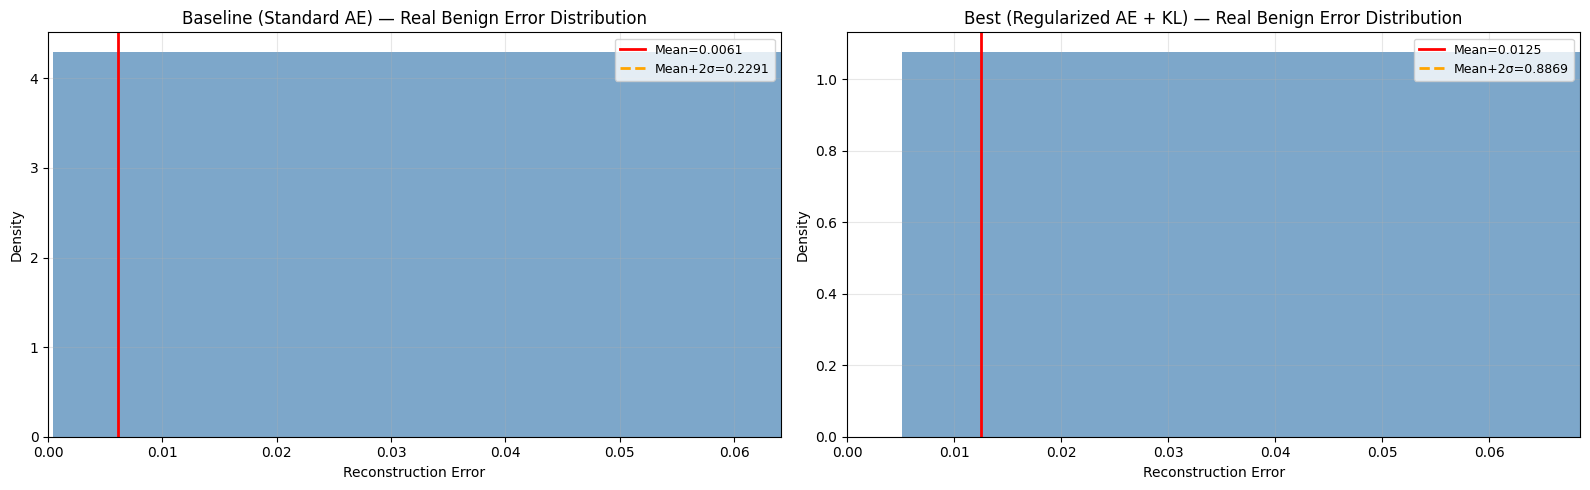

In [7]:
# ── Visualize real data error distribution ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, errors, stats, th, title in zip(
    axes,
    [errors_baseline_real, errors_best_real],
    [stats_baseline, stats_best],
    [threshold_baseline, threshold_best],
    ['Baseline (Standard AE)', 'Best (Regularized AE + KL)']
):
    ax.hist(errors, bins=100, alpha=0.7, color='steelblue', density=True)
    ax.axvline(stats['mean'], color='red', linestyle='-', linewidth=2, label=f"Mean={stats['mean']:.4f}")
    ax.axvline(th, color='orange', linestyle='--', linewidth=2, label=f"Mean+2σ={th:.4f}")
    ax.set_xlabel('Reconstruction Error')
    ax.set_ylabel('Density')
    ax.set_title(f'{title} — Real Benign Error Distribution')
    ax.legend(fontsize=9)
    ax.set_xlim(0, np.percentile(errors, 99.5))
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/real_error_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 5: Load Synthetic Data (ReALTabFormer)

In [8]:
# ── Load synthetic attack sequences ──
synthetic_df = pd.read_excel('ckc_attack_sequences.xlsx')

print("="*70)
print("SYNTHETIC DATA LOADED")
print("="*70)
print(f"Shape: {synthetic_df.shape}")
print(f"Columns: {list(synthetic_df.columns)}")
print(f"\nFirst 5 rows:")
display(synthetic_df.head())

SYNTHETIC DATA LOADED
Shape: (2016, 64)
Columns: ['sequence_id', 'step_idx', 'ckc_stage', 'mitre_tactic', 'mitre_id', 'source_type', 'rule_description', 'command', 'full_log', 'log_secbert_emb_0', 'log_secbert_emb_1', 'log_secbert_emb_2', 'log_secbert_emb_3', 'log_secbert_emb_4', 'log_secbert_emb_5', 'log_secbert_emb_6', 'log_secbert_emb_7', 'log_secbert_emb_8', 'log_secbert_emb_9', 'log_secbert_emb_10', 'log_secbert_emb_11', 'log_secbert_emb_12', 'log_secbert_emb_13', 'log_secbert_emb_14', 'log_secbert_emb_15', 'decoder_auditd', 'firedtimes', 'location__var_log_audit_audit.log', 'srcip_is_private', 'decoder_web-accesslog', 'location__var_log_apache2_access.log', 'firedtimes_log', 'path_is_missing', 'has_md5', 'cmd_length', 'has_sha256', 'syscheck_added', 'cmd_is_missing', 'decoder_dpkg-decoder', 'syscheck_deleted', 'path_depth', 'syscheck_modified', 'location__var_log_auth.log', 'cmd_secbert_emb_0', 'cmd_secbert_emb_1', 'cmd_secbert_emb_2', 'cmd_secbert_emb_3', 'cmd_secbert_emb_4', 'c

,sequence_id,step_idx,ckc_stage,mitre_tactic,mitre_id,source_type,rule_description,command,full_log,log_secbert_emb_0,...,cmd_secbert_emb_11,cmd_secbert_emb_12,cmd_secbert_emb_13,cmd_secbert_emb_14,cmd_secbert_emb_15,decoder_syscheck_deleted,path_is_sensitive,decoder_syscheck_integrity_changed,location_syscheck,path_is_temp
0,0,0,S3,"[""TA0001""]","[""T1190""]",network,A web attack returned code 200 (success).,NaN,192.168.204.1 - - [20/Oct/2023:23:29:41 +0500]...,-6.0000,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,0,1,S4,"[""TA0002""]","[""T1059.007""]",network,XSS (Cross Site Scripting) attempt.,NaN,192.168.204.1 - - [20/Oct/2023:23:25:40 +0500]...,-6.0000,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,0,2,S5,"[""TA0005"",""TA0040""]","[""T1070.004"",""T1485""]",syscheck,File deleted.,NaN,File '/tmp/server-0.xkm' deleted\nMode: realti...,-11.0000,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
3,0,3,S6,"[""TA0008""]","[""T1040"",""T1203"",""T1543"",""T1543.002""]",sca,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0: E...,CIS Ubuntu Linux 22.04 LTS Benchmark v1.0.0,,-10.5492,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,0,4,S7,"[""TA0040""]","[""T1565.001""]",syscheck,Integrity checksum changed.,NaN,File '/tmp/0bff46518b35ddfe37f4a7820286aab829d...,-10.0000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0


In [11]:
# ── Extract the 55 feature columns that match the autoencoder input ──
# Check which selected columns exist in synthetic data
available_cols = [c for c in selected_columns if c in synthetic_df.columns]
missing_cols = [c for c in selected_columns if c not in synthetic_df.columns]

print(f"Selected columns expected: {len(selected_columns)}")
print(f"Available in synthetic data: {len(available_cols)}")

if missing_cols:
    print(f"\n⚠️ Missing columns ({len(missing_cols)}):")
    for c in missing_cols:
        print(f"  - {c}")
    print("\nThese will be filled with 0.0 (neutral value after scaling).")
else:
    print("\n✅ All 55 feature columns found in synthetic data!")

# ── Build synthetic feature matrix ──
X_synthetic_df = pd.DataFrame(0.0, index=synthetic_df.index, columns=selected_columns)
for col in available_cols:
    X_synthetic_df[col] = synthetic_df[col].values

# ── Handle NaN values ──
nan_count = X_synthetic_df.isna().sum().sum()
if nan_count > 0:
    print(f"\n⚠️ Found {nan_count} NaN values in synthetic features — filling with 0.0")
    X_synthetic_df = X_synthetic_df.fillna(0.0)

X_synthetic = X_synthetic_df.values.astype(np.float32)

# ── Scale using the SAME scaler fitted on real data ──
X_synthetic_scaled = scaler.transform(X_synthetic).astype(np.float32)

# Replace any remaining inf/nan after scaling
if np.isnan(X_synthetic_scaled).any() or np.isinf(X_synthetic_scaled).any():
    print("⚠️ Found NaN/Inf after scaling — replacing with 0.0")
    X_synthetic_scaled = np.nan_to_num(X_synthetic_scaled, nan=0.0, posinf=0.0, neginf=0.0)

print(f"\nSynthetic feature matrix: {X_synthetic_scaled.shape}")
print(f"All synthetic samples are MALICIOUS (attack sequences)")

if 'ckc_stage' in synthetic_df.columns:
    print(f"\nCKC stage distribution:")
    print(synthetic_df['ckc_stage'].value_counts().sort_index())

if 'sequence_id' in synthetic_df.columns:
    print(f"\nNumber of attack sequences: {synthetic_df['sequence_id'].nunique()}")

Selected columns expected: 55
Available in synthetic data: 55

✅ All 55 feature columns found in synthetic data!

⚠️ Found 26837 NaN values in synthetic features — filling with 0.0

Synthetic feature matrix: (2016, 55)
All synthetic samples are MALICIOUS (attack sequences)

CKC stage distribution:
ckc_stage
S1    186
S3    265
S4    386
S5    368
S6    311
S7    500
Name: count, dtype: int64

Number of attack sequences: 500


---
## Part 6: Filter Synthetic Samples by Reconstruction Error

In [12]:
# ── Compute reconstruction errors on synthetic data using BOTH models ──
errors_baseline_synth = compute_recon_errors_standard(model_baseline, X_synthetic_scaled, device)
errors_best_synth = compute_recon_errors_regularized(model_best, X_synthetic_scaled, beta=1e-3, device=device)

print("="*70)
print("SYNTHETIC DATA RECONSTRUCTION ERRORS")
print("="*70)
print(f"{'Metric':<20} {'Baseline (Std AE)':>20} {'Best (Reg AE+KL)':>20}")
print("-"*62)
for label, vals_b, vals_r in [
    ('Mean', errors_baseline_synth.mean(), errors_best_synth.mean()),
    ('Std', errors_baseline_synth.std(), errors_best_synth.std()),
    ('Median', np.median(errors_baseline_synth), np.median(errors_best_synth)),
    ('P95', np.percentile(errors_baseline_synth, 95), np.percentile(errors_best_synth, 95)),
    ('P99', np.percentile(errors_baseline_synth, 99), np.percentile(errors_best_synth, 99)),
]:
    print(f"{label:<20} {vals_b:>20.6f} {vals_r:>20.6f}")

SYNTHETIC DATA RECONSTRUCTION ERRORS
Metric                  Baseline (Std AE)     Best (Reg AE+KL)
--------------------------------------------------------------
Mean                             4.450948       1923095.375000
Std                             10.551444      47903788.000000
Median                           1.570461             1.366701
P95                             16.123249            17.694723
P99                             43.375519            45.076935


In [13]:
# ── Filter: keep synthetic samples whose error is within real-data distribution ──
# Using the best model (Regularized AE) for filtering
filter_threshold = threshold_best  # mean + 2*std of real benign errors

# Synthetic data that "looks realistic" = error within real distribution
mask_keep = errors_best_synth <= filter_threshold

X_synthetic_filtered = X_synthetic_scaled[mask_keep]
errors_filtered = errors_best_synth[mask_keep]

print("="*70)
print("SYNTHETIC DATA FILTERING (using Regularized AE threshold)")
print("="*70)
print(f"Filter threshold (mean + 2σ): {filter_threshold:.6f}")
print(f"Total synthetic samples:  {len(X_synthetic_scaled):,}")
print(f"Kept (within distribution): {mask_keep.sum():,} ({mask_keep.mean()*100:.1f}%)")
print(f"Removed (outliers):         {(~mask_keep).sum():,} ({(~mask_keep).mean()*100:.1f}%)")

# Also filter with a more lenient threshold: mean + 3*std
filter_threshold_3s = stats_best['mean'] + 3 * stats_best['std']
mask_keep_3s = errors_best_synth <= filter_threshold_3s
print(f"\nWith mean+3σ ({filter_threshold_3s:.6f}): {mask_keep_3s.sum():,} kept ({mask_keep_3s.mean()*100:.1f}%)")

# Use the more lenient threshold if too few pass strict filter
if mask_keep.sum() < 50:
    print("\n⚠️ Too few samples passed strict filter, using mean+3σ threshold.")
    mask_keep = mask_keep_3s
    X_synthetic_filtered = X_synthetic_scaled[mask_keep]
    errors_filtered = errors_best_synth[mask_keep]
    filter_threshold = filter_threshold_3s

SYNTHETIC DATA FILTERING (using Regularized AE threshold)
Filter threshold (mean + 2σ): 0.886851
Total synthetic samples:  2,016
Kept (within distribution): 254 (12.6%)
Removed (outliers):         1,762 (87.4%)

With mean+3σ (1.324008): 969 kept (48.1%)


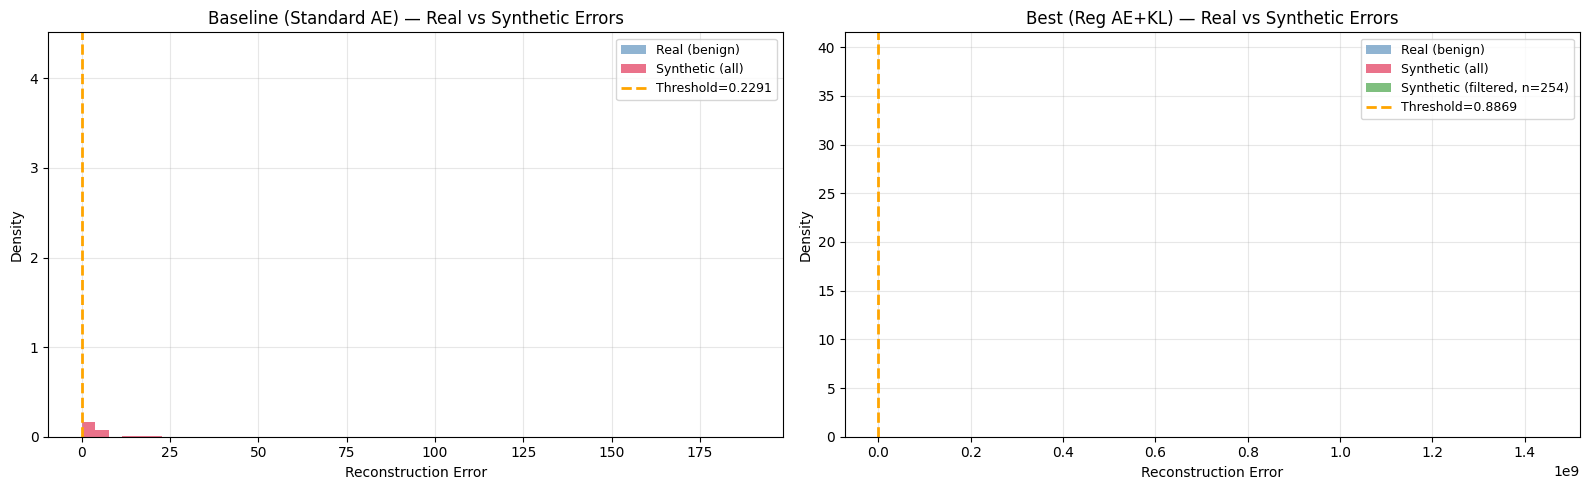

In [14]:
# ── Visualize: real vs synthetic error distributions ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Baseline model
ax = axes[0]
ax.hist(errors_baseline_real, bins=100, alpha=0.6, color='steelblue', density=True, label='Real (benign)')
ax.hist(errors_baseline_synth, bins=50, alpha=0.6, color='crimson', density=True, label='Synthetic (all)')
ax.axvline(threshold_baseline, color='orange', linestyle='--', linewidth=2, label=f'Threshold={threshold_baseline:.4f}')
ax.set_xlabel('Reconstruction Error')
ax.set_ylabel('Density')
ax.set_title('Baseline (Standard AE) — Real vs Synthetic Errors')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Best model
ax = axes[1]
ax.hist(errors_best_real, bins=100, alpha=0.6, color='steelblue', density=True, label='Real (benign)')
ax.hist(errors_best_synth, bins=50, alpha=0.6, color='crimson', density=True, label='Synthetic (all)')
ax.hist(errors_filtered, bins=50, alpha=0.5, color='green', density=True, label=f'Synthetic (filtered, n={len(errors_filtered)})')
ax.axvline(filter_threshold, color='orange', linestyle='--', linewidth=2, label=f'Threshold={filter_threshold:.4f}')
ax.set_xlabel('Reconstruction Error')
ax.set_ylabel('Density')
ax.set_title('Best (Reg AE+KL) — Real vs Synthetic Errors')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/real_vs_synthetic_error_dist.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 7: Create Mixed Datasets (Real + Filtered Synthetic)

In [15]:
def create_mixed_dataset(X_real, X_synthetic, synthetic_ratio=0.3):
    """
    Create a mixed dataset with a given real/synthetic ratio.
    synthetic_ratio: fraction of total data that should be synthetic.
    Returns: X_mixed, is_synthetic (boolean mask)
    """
    n_real = len(X_real)
    n_synth_desired = int(n_real * synthetic_ratio / (1 - synthetic_ratio))
    n_synth_available = len(X_synthetic)
    
    if n_synth_desired > n_synth_available:
        # Repeat synthetic data if not enough
        repeats = (n_synth_desired // n_synth_available) + 1
        X_synth_pool = np.tile(X_synthetic, (repeats, 1))[:n_synth_desired]
    else:
        # Randomly sample
        idx = np.random.choice(n_synth_available, n_synth_desired, replace=False)
        X_synth_pool = X_synthetic[idx]
    
    X_mixed = np.vstack([X_real, X_synth_pool])
    is_synthetic = np.array([False]*n_real + [True]*len(X_synth_pool))
    
    # Shuffle
    perm = np.random.permutation(len(X_mixed))
    return X_mixed[perm].astype(np.float32), is_synthetic[perm]


# ── Create mixed datasets with different ratios ──
X_mixed_20, is_synth_20 = create_mixed_dataset(X_train_real, X_synthetic_filtered, synthetic_ratio=0.20)
X_mixed_30, is_synth_30 = create_mixed_dataset(X_train_real, X_synthetic_filtered, synthetic_ratio=0.30)

print("="*70)
print("MIXED DATASETS CREATED")
print("="*70)
print(f"{'Dataset':<35} {'Total':>8} {'Real':>8} {'Synthetic':>10} {'Synth %':>8}")
print("-"*70)
print(f"{'Real only (baseline)':<35} {len(X_train_real):>8,} {len(X_train_real):>8,} {0:>10} {'0.0%':>8}")
print(f"{'Real + 20% Synthetic':<35} {len(X_mixed_20):>8,} {(~is_synth_20).sum():>8,} {is_synth_20.sum():>10,} {is_synth_20.mean()*100:>7.1f}%")
print(f"{'Real + 30% Synthetic':<35} {len(X_mixed_30):>8,} {(~is_synth_30).sum():>8,} {is_synth_30.sum():>10,} {is_synth_30.mean()*100:>7.1f}%")

MIXED DATASETS CREATED
Dataset                                Total     Real  Synthetic  Synth %
----------------------------------------------------------------------
Real only (baseline)                  72,246   72,246          0     0.0%
Real + 20% Synthetic                  90,307   72,246     18,061    20.0%
Real + 30% Synthetic                 103,208   72,246     30,962    30.0%


---
## Part 8: Training & Evaluation Utility Functions

In [16]:
def create_dataloader(X, batch_size=256, shuffle=True):
    tensor = torch.FloatTensor(X)
    return DataLoader(TensorDataset(tensor, tensor), batch_size=batch_size, shuffle=shuffle)


def find_threshold_youden(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    j = tpr - fpr
    return thresholds[np.argmax(j)]


def evaluate_anomaly_detection(model, X_test, y_true, is_regularized=False, beta=1e-3, device='cpu'):
    """
    Full anomaly detection evaluation pipeline.
    Returns dict of metrics.
    """
    if is_regularized:
        scores = compute_recon_errors_regularized(model, X_test, beta=beta, device=device)
    else:
        scores = compute_recon_errors_standard(model, X_test, device=device)
    
    threshold = find_threshold_youden(y_true, scores)
    preds = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    
    return {
        'ROC-AUC': roc_auc_score(y_true, scores),
        'AP': average_precision_score(y_true, scores),
        'Balanced Acc': balanced_accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall': recall_score(y_true, preds, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
        'F1': f1_score(y_true, preds, zero_division=0),
        'Threshold': threshold,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'scores': scores,
    }


print("Utility functions defined.")

Utility functions defined.


---
## Part 9: Experiment 1 — Real Data Only (Baseline)

These are the pretrained models from TP1. We simply evaluate them here as the reference baseline.

In [17]:
print("="*70)
print("EXPERIMENT 1: Real Data Only (Pretrained Baseline)")
print("="*70)

# Evaluate on REAL test data (all samples: benign + malicious)
results_real_baseline = evaluate_anomaly_detection(
    model_baseline, X_real_scaled, y_malicious, is_regularized=False, device=device
)
results_real_best = evaluate_anomaly_detection(
    model_best, X_real_scaled, y_malicious, is_regularized=True, beta=1e-3, device=device
)

print(f"\n{'Model':<35} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10} {'Precision':>10} {'Recall':>10}")
print("-"*85)
for name, m in [('Standard AE (Real Only)', results_real_baseline),
                ('Regularized AE (Real Only)', results_real_best)]:
    print(f"{name:<35} {m['ROC-AUC']:>10.4f} {m['F1']:>10.4f} {m['Balanced Acc']:>10.4f} {m['Precision']:>10.4f} {m['Recall']:>10.4f}")

EXPERIMENT 1: Real Data Only (Pretrained Baseline)

Model                                  ROC-AUC         F1    Bal.Acc  Precision     Recall
-------------------------------------------------------------------------------------
Standard AE (Real Only)                 0.9821     0.8602     0.9370     0.7893     0.9450
Regularized AE (Real Only)              0.9849     0.8732     0.9452     0.8034     0.9562


---
## Part 10: Experiment 2 — Test Pretrained Models on Synthetic Data

Run the real-data-trained autoencoders on synthetic data to see how well they detect synthetic attacks.

In [18]:
print("="*70)
print("EXPERIMENT 2: Test Pretrained Models on Synthetic Data")
print("="*70)

# All synthetic data is malicious → y_synth = all 1s
y_synthetic_all = np.ones(len(X_synthetic_scaled), dtype=int)

# We need some benign data for meaningful metrics — combine real benign + synthetic malicious
X_test_synth_combined = np.vstack([X_real_scaled[benign_mask], X_synthetic_scaled])
y_test_synth_combined = np.concatenate([np.zeros(benign_mask.sum()), y_synthetic_all])

results_synth_baseline = evaluate_anomaly_detection(
    model_baseline, X_test_synth_combined, y_test_synth_combined,
    is_regularized=False, device=device
)
results_synth_best = evaluate_anomaly_detection(
    model_best, X_test_synth_combined, y_test_synth_combined,
    is_regularized=True, beta=1e-3, device=device
)

print(f"\nTest set: {benign_mask.sum():,} real benign + {len(X_synthetic_scaled):,} synthetic malicious")
print(f"\n{'Model':<35} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10} {'Precision':>10} {'Recall':>10}")
print("-"*85)
for name, m in [('Standard AE (on Synthetic)', results_synth_baseline),
                ('Regularized AE (on Synthetic)', results_synth_best)]:
    print(f"{name:<35} {m['ROC-AUC']:>10.4f} {m['F1']:>10.4f} {m['Balanced Acc']:>10.4f} {m['Precision']:>10.4f} {m['Recall']:>10.4f}")

# Detection rate on synthetic-only
errors_synth_baseline_only = compute_recon_errors_standard(model_baseline, X_synthetic_scaled, device)
errors_synth_best_only = compute_recon_errors_regularized(model_best, X_synthetic_scaled, beta=1e-3, device=device)

th_b = results_real_baseline['Threshold']
th_r = results_real_best['Threshold']
det_rate_b = (errors_synth_baseline_only > th_b).mean() * 100
det_rate_r = (errors_synth_best_only > th_r).mean() * 100

print(f"\nSynthetic data detection rate (using real-data thresholds):")
print(f"  Standard AE:     {det_rate_b:.1f}% detected as anomalous")
print(f"  Regularized AE:  {det_rate_r:.1f}% detected as anomalous")

EXPERIMENT 2: Test Pretrained Models on Synthetic Data

Test set: 90,308 real benign + 2,016 synthetic malicious

Model                                  ROC-AUC         F1    Bal.Acc  Precision     Recall
-------------------------------------------------------------------------------------
Standard AE (on Synthetic)              0.9998     0.9782     0.9993     0.9577     0.9995
Regularized AE (on Synthetic)           0.9998     0.9648     0.9989     0.9324     0.9995

Synthetic data detection rate (using real-data thresholds):
  Standard AE:     100.0% detected as anomalous
  Regularized AE:  100.0% detected as anomalous


---
## Part 11: Experiment 3 — Fine-tune with Real + 20% Synthetic Data

In [19]:
def finetune_standard_ae(pretrained_model, train_loader, val_loader,
                         epochs=50, lr=1e-4, patience=10, device='cpu'):
    """
    Fine-tune a pretrained Standard AE with a smaller learning rate.
    """
    model = copy.deepcopy(pretrained_model).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for bx, _ in train_loader:
            bx = bx.to(device)
            x_hat, _ = model(bx)
            loss = criterion(x_hat, bx)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * bx.size(0)
        train_loss /= len(train_loader.dataset)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device)
                x_hat, _ = model(bx)
                val_loss += criterion(x_hat, bx).item() * bx.size(0)
        val_loss /= len(val_loader.dataset)
        
        scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {train_loss:.6f} | Val: {val_loss:.6f}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


def finetune_regularized_ae(pretrained_model, train_loader, val_loader,
                            epochs=50, lr=1e-4, beta=1e-3, gamma=1e-2,
                            patience=10, device='cpu'):
    """
    Fine-tune a pretrained Regularized AE with a smaller learning rate.
    """
    model = copy.deepcopy(pretrained_model).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0; n = 0
        for bx, _ in train_loader:
            bx = bx.to(device); bs = bx.size(0)
            x_hat, z, mu, logvar = model(bx)
            l_r = criterion(x_hat, bx)
            l_k = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
            l_c = ((z - model.center)**2).sum(dim=1).mean()
            loss = l_r + beta * l_k + gamma * l_c
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * bs; n += bs
        total_loss /= n
        
        model.eval()
        val_loss = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z, mu, logvar = model(bx)
                l_r = criterion(x_hat, bx)
                l_k = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
                l_c = ((z - model.center)**2).sum(dim=1).mean()
                val_loss += (l_r + beta*l_k + gamma*l_c).item() * bs; nv += bs
        val_loss /= nv
        
        scheduler.step(val_loss)
        history['train_loss'].append(total_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {total_loss:.6f} | Val: {val_loss:.6f}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


print("Fine-tuning functions defined.")

Fine-tuning functions defined.


In [20]:
print("="*70)
print("EXPERIMENT 3: Fine-tune with Real + 20% Synthetic")
print("="*70)

train_loader_20 = create_dataloader(X_mixed_20, batch_size=256, shuffle=True)
val_loader = create_dataloader(X_val_real, batch_size=256, shuffle=False)

# Fine-tune Standard AE
print("\n--- Standard AE (Fine-tune, lr=1e-4) ---")
model_ft_std_20, hist_ft_std_20 = finetune_standard_ae(
    model_baseline, train_loader_20, val_loader,
    epochs=50, lr=1e-4, patience=10, device=device
)

# Fine-tune Regularized AE
print("\n--- Regularized AE (Fine-tune, lr=1e-4) ---")
model_ft_reg_20, hist_ft_reg_20 = finetune_regularized_ae(
    model_best, train_loader_20, val_loader,
    epochs=50, lr=1e-4, beta=1e-3, gamma=1e-2, patience=10, device=device
)

# Evaluate
results_ft_std_20 = evaluate_anomaly_detection(model_ft_std_20, X_real_scaled, y_malicious, is_regularized=False, device=device)
results_ft_reg_20 = evaluate_anomaly_detection(model_ft_reg_20, X_real_scaled, y_malicious, is_regularized=True, beta=1e-3, device=device)

print(f"\n{'Model':<40} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10}")
print("-"*70)
print(f"{'Std AE FT (Real+20% Synth)':<40} {results_ft_std_20['ROC-AUC']:>10.4f} {results_ft_std_20['F1']:>10.4f} {results_ft_std_20['Balanced Acc']:>10.4f}")
print(f"{'Reg AE FT (Real+20% Synth)':<40} {results_ft_reg_20['ROC-AUC']:>10.4f} {results_ft_reg_20['F1']:>10.4f} {results_ft_reg_20['Balanced Acc']:>10.4f}")

EXPERIMENT 3: Fine-tune with Real + 20% Synthetic

--- Standard AE (Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.084771 | Val: 0.013558
  Epoch [ 10/50] Train: 0.032105 | Val: 0.006699
  Epoch [ 20/50] Train: 0.030109 | Val: 0.006550
  Epoch [ 30/50] Train: 0.028832 | Val: 0.005968
  Epoch [ 40/50] Train: 0.028308 | Val: 0.005607
  Early stop at epoch 42
  Best val loss: 0.005472

--- Regularized AE (Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.084079 | Val: 0.018635
  Epoch [ 10/50] Train: 0.042474 | Val: 0.012712
  Epoch [ 20/50] Train: 0.039528 | Val: 0.012523
  Epoch [ 30/50] Train: 0.038484 | Val: 0.012680
  Epoch [ 40/50] Train: 0.037852 | Val: 0.014906
  Epoch [ 50/50] Train: 0.037969 | Val: 0.015231
  Best val loss: 0.011504

Model                                       ROC-AUC         F1    Bal.Acc
----------------------------------------------------------------------
Std AE FT (Real+20% Synth)                   0.9852     0.8788     0.9450
Reg AE FT (Real+20% Synth) 

---
## Part 12: Experiment 4 — Fine-tune with Real + 30% Synthetic Data

In [21]:
print("="*70)
print("EXPERIMENT 4: Fine-tune with Real + 30% Synthetic")
print("="*70)

train_loader_30 = create_dataloader(X_mixed_30, batch_size=256, shuffle=True)

# Fine-tune Standard AE
print("\n--- Standard AE (Fine-tune, lr=1e-4) ---")
model_ft_std_30, hist_ft_std_30 = finetune_standard_ae(
    model_baseline, train_loader_30, val_loader,
    epochs=50, lr=1e-4, patience=10, device=device
)

# Fine-tune Regularized AE
print("\n--- Regularized AE (Fine-tune, lr=1e-4) ---")
model_ft_reg_30, hist_ft_reg_30 = finetune_regularized_ae(
    model_best, train_loader_30, val_loader,
    epochs=50, lr=1e-4, beta=1e-3, gamma=1e-2, patience=10, device=device
)

# Evaluate
results_ft_std_30 = evaluate_anomaly_detection(model_ft_std_30, X_real_scaled, y_malicious, is_regularized=False, device=device)
results_ft_reg_30 = evaluate_anomaly_detection(model_ft_reg_30, X_real_scaled, y_malicious, is_regularized=True, beta=1e-3, device=device)

print(f"\n{'Model':<40} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10}")
print("-"*70)
print(f"{'Std AE FT (Real+30% Synth)':<40} {results_ft_std_30['ROC-AUC']:>10.4f} {results_ft_std_30['F1']:>10.4f} {results_ft_std_30['Balanced Acc']:>10.4f}")
print(f"{'Reg AE FT (Real+30% Synth)':<40} {results_ft_reg_30['ROC-AUC']:>10.4f} {results_ft_reg_30['F1']:>10.4f} {results_ft_reg_30['Balanced Acc']:>10.4f}")

EXPERIMENT 4: Fine-tune with Real + 30% Synthetic

--- Standard AE (Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.118672 | Val: 0.019088
  Epoch [ 10/50] Train: 0.034056 | Val: 0.007835
  Epoch [ 20/50] Train: 0.031059 | Val: 0.006790
  Early stop at epoch 29
  Best val loss: 0.006261

--- Regularized AE (Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.111509 | Val: 0.021841
  Epoch [ 10/50] Train: 0.043900 | Val: 0.012870
  Epoch [ 20/50] Train: 0.040260 | Val: 0.013203
  Early stop at epoch 22
  Best val loss: 0.012752

Model                                       ROC-AUC         F1    Bal.Acc
----------------------------------------------------------------------
Std AE FT (Real+30% Synth)                   0.9844     0.8507     0.9390
Reg AE FT (Real+30% Synth)                   0.9839     0.8684     0.9392


---
## Part 13: Experiment 5 — Weighted Reconstruction Loss

Apply per-sample weights during fine-tuning: **real samples get higher weight** than synthetic samples, so the model prioritizes reconstructing real data while still learning from synthetic patterns.

In [22]:
def create_weighted_dataloader(X, is_synthetic, real_weight=1.0, synth_weight=0.3, batch_size=256):
    """
    Create a DataLoader where each sample carries a weight.
    Real samples get real_weight, synthetic samples get synth_weight.
    """
    weights = np.where(is_synthetic, synth_weight, real_weight).astype(np.float32)
    tensor_x = torch.FloatTensor(X)
    tensor_w = torch.FloatTensor(weights)
    dataset = TensorDataset(tensor_x, tensor_w)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)


def finetune_standard_ae_weighted(pretrained_model, train_loader, val_loader,
                                  epochs=50, lr=1e-4, patience=10, device='cpu'):
    """
    Fine-tune Standard AE with per-sample weighted MSE loss.
    """
    model = copy.deepcopy(pretrained_model).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0; total_w = 0.0
        for bx, bw in train_loader:
            bx, bw = bx.to(device), bw.to(device)
            x_hat, _ = model(bx)
            # Per-sample weighted MSE
            per_sample_mse = ((x_hat - bx)**2).mean(dim=1)  # [batch]
            loss = (per_sample_mse * bw).sum() / bw.sum()
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += (per_sample_mse * bw).sum().item()
            total_w += bw.sum().item()
        train_loss = total_loss / total_w
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device)
                x_hat, _ = model(bx)
                val_loss += ((x_hat - bx)**2).mean(dim=1).sum().item()
        val_loss /= len(val_loader.dataset)
        
        scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {train_loss:.6f} | Val: {val_loss:.6f}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


def finetune_regularized_ae_weighted(pretrained_model, train_loader, val_loader,
                                     epochs=50, lr=1e-4, beta=1e-3, gamma=1e-2,
                                     patience=10, device='cpu'):
    """
    Fine-tune Regularized AE with per-sample weighted loss.
    """
    model = copy.deepcopy(pretrained_model).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0; total_w = 0.0
        for bx, bw in train_loader:
            bx, bw = bx.to(device), bw.to(device)
            x_hat, z, mu, logvar = model(bx)
            per_sample_mse = ((x_hat - bx)**2).mean(dim=1)
            per_sample_kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean(dim=1)
            per_sample_center = ((z - model.center)**2).sum(dim=1)
            per_sample_loss = per_sample_mse + beta * per_sample_kl + gamma * per_sample_center
            loss = (per_sample_loss * bw).sum() / bw.sum()
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += (per_sample_loss * bw).sum().item()
            total_w += bw.sum().item()
        train_loss = total_loss / total_w
        
        model.eval()
        val_loss = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z, mu, logvar = model(bx)
                l_r = ((x_hat - bx)**2).mean(dim=1).sum()
                l_k = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).mean(dim=1).sum()
                l_c = ((z - model.center)**2).sum(dim=1).sum()
                val_loss += (l_r + beta*l_k + gamma*l_c).item(); nv += bs
        val_loss /= nv
        
        scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {train_loss:.6f} | Val: {val_loss:.6f}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


print("Weighted fine-tuning functions defined.")

Weighted fine-tuning functions defined.


In [23]:
print("="*70)
print("EXPERIMENT 5: Weighted Loss (Real=1.0, Synthetic=0.3) — 30% Synthetic")
print("="*70)

# Create weighted dataloader (30% synthetic ratio, weights: real=1.0, synth=0.3)
weighted_loader_30 = create_weighted_dataloader(
    X_mixed_30, is_synth_30, real_weight=1.0, synth_weight=0.3, batch_size=256
)

# val_loader uses (x, x) format — need to adapt for weighted functions
val_loader_weighted = create_weighted_dataloader(
    X_val_real, np.zeros(len(X_val_real), dtype=bool),
    real_weight=1.0, synth_weight=0.3, batch_size=256
)

# Fine-tune Standard AE with weighted loss
print("\n--- Standard AE (Weighted Fine-tune, lr=1e-4) ---")
model_wt_std_30, hist_wt_std_30 = finetune_standard_ae_weighted(
    model_baseline, weighted_loader_30, val_loader_weighted,
    epochs=50, lr=1e-4, patience=10, device=device
)

# Fine-tune Regularized AE with weighted loss
print("\n--- Regularized AE (Weighted Fine-tune, lr=1e-4) ---")
model_wt_reg_30, hist_wt_reg_30 = finetune_regularized_ae_weighted(
    model_best, weighted_loader_30, val_loader_weighted,
    epochs=50, lr=1e-4, beta=1e-3, gamma=1e-2, patience=10, device=device
)

# Evaluate
results_wt_std_30 = evaluate_anomaly_detection(model_wt_std_30, X_real_scaled, y_malicious, is_regularized=False, device=device)
results_wt_reg_30 = evaluate_anomaly_detection(model_wt_reg_30, X_real_scaled, y_malicious, is_regularized=True, beta=1e-3, device=device)

print(f"\n{'Model':<45} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10}")
print("-"*75)
print(f"{'Std AE Weighted FT (Real+30% Synth)':<45} {results_wt_std_30['ROC-AUC']:>10.4f} {results_wt_std_30['F1']:>10.4f} {results_wt_std_30['Balanced Acc']:>10.4f}")
print(f"{'Reg AE Weighted FT (Real+30% Synth)':<45} {results_wt_reg_30['ROC-AUC']:>10.4f} {results_wt_reg_30['F1']:>10.4f} {results_wt_reg_30['Balanced Acc']:>10.4f}")

EXPERIMENT 5: Weighted Loss (Real=1.0, Synthetic=0.3) — 30% Synthetic

--- Standard AE (Weighted Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.069243 | Val: 0.010794
  Epoch [ 10/50] Train: 0.029860 | Val: 0.006345
  Epoch [ 20/50] Train: 0.028085 | Val: 0.008061
  Epoch [ 30/50] Train: 0.027806 | Val: 0.005383
  Epoch [ 40/50] Train: 0.027573 | Val: 0.005828
  Early stop at epoch 48
  Best val loss: 0.005151

--- Regularized AE (Weighted Fine-tune, lr=1e-4) ---
  Epoch [  1/50] Train: 0.072698 | Val: 0.015693
  Epoch [ 10/50] Train: 0.039145 | Val: 0.013428
  Epoch [ 20/50] Train: 0.037422 | Val: 0.011395
  Epoch [ 30/50] Train: 0.037151 | Val: 0.011796
  Early stop at epoch 30
  Best val loss: 0.011395

Model                                            ROC-AUC         F1    Bal.Acc
---------------------------------------------------------------------------
Std AE Weighted FT (Real+30% Synth)               0.9854     0.8857     0.9468
Reg AE Weighted FT (Real+30% Synth)            

---
## Part 14: Experiment 6 — Curriculum Learning (Gradual Synthetic Introduction)

Introduce synthetic data **gradually** during training:
- Early epochs: train mostly on real data
- Later epochs: progressively increase synthetic data proportion

In [24]:
def finetune_curriculum_standard_ae(pretrained_model, X_real, X_synthetic,
                                    val_loader, epochs=50, lr=1e-4,
                                    patience=10, device='cpu'):
    """
    Curriculum fine-tuning: gradually increase synthetic data fraction.
    Phase 1 (0-33%): 100% real data only
    Phase 2 (33-66%): real + 15% synthetic
    Phase 3 (66-100%): real + 30% synthetic
    """
    model = copy.deepcopy(pretrained_model).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': [], 'synth_fraction': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    phase_boundaries = [epochs // 3, 2 * epochs // 3]
    synth_ratios = [0.0, 0.15, 0.30]
    
    current_phase = -1
    train_loader = None
    
    for epoch in range(epochs):
        # Determine phase
        if epoch < phase_boundaries[0]:
            phase = 0
        elif epoch < phase_boundaries[1]:
            phase = 1
        else:
            phase = 2
        
        # Rebuild dataloader when phase changes
        if phase != current_phase:
            current_phase = phase
            ratio = synth_ratios[phase]
            if ratio > 0 and len(X_synthetic) > 0:
                X_mix, _ = create_mixed_dataset(X_real, X_synthetic, synthetic_ratio=ratio)
            else:
                X_mix = X_real
            train_loader = create_dataloader(X_mix, batch_size=256, shuffle=True)
            print(f"  Phase {phase+1}: epochs {epoch+1}+ → synth_ratio={ratio:.0%} → {len(X_mix):,} samples")
        
        history['synth_fraction'].append(synth_ratios[phase])
        
        model.train()
        train_loss = 0.0
        for bx, _ in train_loader:
            bx = bx.to(device)
            x_hat, _ = model(bx)
            loss = criterion(x_hat, bx)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * bx.size(0)
        train_loss /= len(train_loader.dataset)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device)
                x_hat, _ = model(bx)
                val_loss += criterion(x_hat, bx).item() * bx.size(0)
        val_loss /= len(val_loader.dataset)
        
        scheduler.step(val_loss)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {train_loss:.6f} | Val: {val_loss:.6f} | Synth: {synth_ratios[phase]:.0%}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


def finetune_curriculum_regularized_ae(pretrained_model, X_real, X_synthetic,
                                       val_loader, epochs=50, lr=1e-4,
                                       beta=1e-3, gamma=1e-2,
                                       patience=10, device='cpu'):
    """
    Curriculum fine-tuning for Regularized AE.
    """
    model = copy.deepcopy(pretrained_model).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
    
    history = {'train_loss': [], 'val_loss': [], 'synth_fraction': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0
    
    phase_boundaries = [epochs // 3, 2 * epochs // 3]
    synth_ratios = [0.0, 0.15, 0.30]
    
    current_phase = -1
    train_loader = None
    
    for epoch in range(epochs):
        if epoch < phase_boundaries[0]:
            phase = 0
        elif epoch < phase_boundaries[1]:
            phase = 1
        else:
            phase = 2
        
        if phase != current_phase:
            current_phase = phase
            ratio = synth_ratios[phase]
            if ratio > 0 and len(X_synthetic) > 0:
                X_mix, _ = create_mixed_dataset(X_real, X_synthetic, synthetic_ratio=ratio)
            else:
                X_mix = X_real
            train_loader = create_dataloader(X_mix, batch_size=256, shuffle=True)
            print(f"  Phase {phase+1}: epochs {epoch+1}+ → synth_ratio={ratio:.0%} → {len(X_mix):,} samples")
        
        history['synth_fraction'].append(synth_ratios[phase])
        
        model.train()
        total_loss = 0.0; n = 0
        for bx, _ in train_loader:
            bx = bx.to(device); bs = bx.size(0)
            x_hat, z, mu, logvar = model(bx)
            l_r = criterion(x_hat, bx)
            l_k = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
            l_c = ((z - model.center)**2).sum(dim=1).mean()
            loss = l_r + beta * l_k + gamma * l_c
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * bs; n += bs
        total_loss /= n
        
        model.eval()
        val_loss = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z, mu, logvar = model(bx)
                l_r = criterion(x_hat, bx)
                l_k = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
                l_c = ((z - model.center)**2).sum(dim=1).mean()
                val_loss += (l_r + beta*l_k + gamma*l_c).item() * bs; nv += bs
        val_loss /= nv
        
        scheduler.step(val_loss)
        history['train_loss'].append(total_loss)
        history['val_loss'].append(val_loss)
        
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] Train: {total_loss:.6f} | Val: {val_loss:.6f} | Synth: {synth_ratios[phase]:.0%}")
        
        if val_loss < best_val:
            best_val = val_loss; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break
    
    if best_state: model.load_state_dict(best_state)
    print(f"  Best val loss: {best_val:.6f}")
    return model, history


print("Curriculum fine-tuning functions defined.")

Curriculum fine-tuning functions defined.


In [25]:
print("="*70)
print("EXPERIMENT 6: Curriculum Learning (Gradual Synthetic Introduction)")
print("="*70)

val_loader_cur = create_dataloader(X_val_real, batch_size=256, shuffle=False)

# Standard AE — Curriculum
print("\n--- Standard AE (Curriculum, lr=1e-4) ---")
model_cur_std, hist_cur_std = finetune_curriculum_standard_ae(
    model_baseline, X_train_real, X_synthetic_filtered,
    val_loader_cur, epochs=60, lr=1e-4, patience=12, device=device
)

# Regularized AE — Curriculum
print("\n--- Regularized AE (Curriculum, lr=1e-4) ---")
model_cur_reg, hist_cur_reg = finetune_curriculum_regularized_ae(
    model_best, X_train_real, X_synthetic_filtered,
    val_loader_cur, epochs=60, lr=1e-4, beta=1e-3, gamma=1e-2, patience=12, device=device
)

# Evaluate
results_cur_std = evaluate_anomaly_detection(model_cur_std, X_real_scaled, y_malicious, is_regularized=False, device=device)
results_cur_reg = evaluate_anomaly_detection(model_cur_reg, X_real_scaled, y_malicious, is_regularized=True, beta=1e-3, device=device)

print(f"\n{'Model':<45} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10}")
print("-"*75)
print(f"{'Std AE Curriculum FT':<45} {results_cur_std['ROC-AUC']:>10.4f} {results_cur_std['F1']:>10.4f} {results_cur_std['Balanced Acc']:>10.4f}")
print(f"{'Reg AE Curriculum FT':<45} {results_cur_reg['ROC-AUC']:>10.4f} {results_cur_reg['F1']:>10.4f} {results_cur_reg['Balanced Acc']:>10.4f}")

EXPERIMENT 6: Curriculum Learning (Gradual Synthetic Introduction)

--- Standard AE (Curriculum, lr=1e-4) ---
  Phase 1: epochs 1+ → synth_ratio=0% → 72,246 samples
  Epoch [  1/60] Train: 0.020937 | Val: 0.004387 | Synth: 0%
  Epoch [ 10/60] Train: 0.020740 | Val: 0.004677 | Synth: 0%
  Early stop at epoch 13
  Best val loss: 0.004387

--- Regularized AE (Curriculum, lr=1e-4) ---
  Phase 1: epochs 1+ → synth_ratio=0% → 72,246 samples
  Epoch [  1/60] Train: 0.029963 | Val: 0.011178 | Synth: 0%
  Epoch [ 10/60] Train: 0.029877 | Val: 0.010864 | Synth: 0%
  Early stop at epoch 17
  Best val loss: 0.010264

Model                                            ROC-AUC         F1    Bal.Acc
---------------------------------------------------------------------------
Std AE Curriculum FT                              0.9817     0.8653     0.9315
Reg AE Curriculum FT                              0.9814     0.8709     0.9414


---
## Part 15: Comprehensive Results Comparison

In [26]:
# ── Collect all experiment results ──
all_experiments = {
    # Experiment 1: Real Only (baseline)
    'Std AE — Real Only (baseline)':   results_real_baseline,
    'Reg AE — Real Only (baseline)':   results_real_best,
    # Experiment 3: Real + 20% Synthetic
    'Std AE — FT Real+20% Synth':     results_ft_std_20,
    'Reg AE — FT Real+20% Synth':     results_ft_reg_20,
    # Experiment 4: Real + 30% Synthetic
    'Std AE — FT Real+30% Synth':     results_ft_std_30,
    'Reg AE — FT Real+30% Synth':     results_ft_reg_30,
    # Experiment 5: Weighted Loss
    'Std AE — Weighted FT 30%':       results_wt_std_30,
    'Reg AE — Weighted FT 30%':       results_wt_reg_30,
    # Experiment 6: Curriculum
    'Std AE — Curriculum FT':         results_cur_std,
    'Reg AE — Curriculum FT':         results_cur_reg,
}

# Remove 'scores' key for table display
display_results = {}
for name, metrics in all_experiments.items():
    display_results[name] = {k: v for k, v in metrics.items() if k != 'scores'}

print("="*120)
print(f"{'COMPREHENSIVE EXPERIMENT COMPARISON':^120}")
print("="*120)
print(f"{'Experiment':<40} {'ROC-AUC':>10} {'AP':>10} {'F1':>10} {'Bal.Acc':>10} {'Prec':>10} {'Recall':>10} {'Spec':>10}")
print("-"*120)
for name, m in display_results.items():
    print(f"{name:<40} {m['ROC-AUC']:>10.4f} {m['AP']:>10.4f} {m['F1']:>10.4f} {m['Balanced Acc']:>10.4f} "
          f"{m['Precision']:>10.4f} {m['Recall']:>10.4f} {m['Specificity']:>10.4f}")
print("="*120)

# Best model overall
best_name = max(display_results, key=lambda x: display_results[x]['ROC-AUC'])
best_auc = display_results[best_name]['ROC-AUC']
print(f"\nBEST MODEL: {best_name}  (ROC-AUC: {best_auc:.4f})")

                                          COMPREHENSIVE EXPERIMENT COMPARISON                                           
Experiment                                  ROC-AUC         AP         F1    Bal.Acc       Prec     Recall       Spec
------------------------------------------------------------------------------------------------------------------------
Std AE — Real Only (baseline)                0.9821     0.9491     0.8602     0.9370     0.7893     0.9450     0.9290
Reg AE — Real Only (baseline)                0.9849     0.9553     0.8732     0.9452     0.8034     0.9562     0.9341
Std AE — FT Real+20% Synth                   0.9852     0.9582     0.8788     0.9450     0.8181     0.9494     0.9406
Reg AE — FT Real+20% Synth                   0.9831     0.9472     0.8541     0.9380     0.7723     0.9553     0.9207
Std AE — FT Real+30% Synth                   0.9844     0.9559     0.8507     0.9390     0.7621     0.9626     0.9154
Reg AE — FT Real+30% Synth                   0.983

In [27]:
# ── Deltas vs Baseline ──
print("="*90)
print(f"{'DELTAS vs BASELINE (Real Only)':^90}")
print("="*90)

# Standard AE deltas
base_std = display_results['Std AE — Real Only (baseline)']
print(f"\n{'STANDARD AE Experiments':}")
print(f"{'Experiment':<40} {'ΔROC-AUC':>12} {'ΔF1':>12} {'ΔBal.Acc':>12}")
print("-"*76)
for name, m in display_results.items():
    if name.startswith('Std AE') and name != 'Std AE — Real Only (baseline)':
        dr = m['ROC-AUC'] - base_std['ROC-AUC']
        df = m['F1'] - base_std['F1']
        db = m['Balanced Acc'] - base_std['Balanced Acc']
        print(f"{name:<40} {dr:>+12.4f} {df:>+12.4f} {db:>+12.4f}")

# Regularized AE deltas
base_reg = display_results['Reg AE — Real Only (baseline)']
print(f"\n{'REGULARIZED AE Experiments':}")
print(f"{'Experiment':<40} {'ΔROC-AUC':>12} {'ΔF1':>12} {'ΔBal.Acc':>12}")
print("-"*76)
for name, m in display_results.items():
    if name.startswith('Reg AE') and name != 'Reg AE — Real Only (baseline)':
        dr = m['ROC-AUC'] - base_reg['ROC-AUC']
        df = m['F1'] - base_reg['F1']
        db = m['Balanced Acc'] - base_reg['Balanced Acc']
        print(f"{name:<40} {dr:>+12.4f} {df:>+12.4f} {db:>+12.4f}")

                              DELTAS vs BASELINE (Real Only)                              

STANDARD AE Experiments
Experiment                                   ΔROC-AUC          ΔF1     ΔBal.Acc
----------------------------------------------------------------------------
Std AE — FT Real+20% Synth                    +0.0031      +0.0187      +0.0080
Std AE — FT Real+30% Synth                    +0.0023      -0.0095      +0.0020
Std AE — Weighted FT 30%                      +0.0033      +0.0255      +0.0098
Std AE — Curriculum FT                        -0.0003      +0.0051      -0.0055

REGULARIZED AE Experiments
Experiment                                   ΔROC-AUC          ΔF1     ΔBal.Acc
----------------------------------------------------------------------------
Reg AE — FT Real+20% Synth                    -0.0018      -0.0190      -0.0071
Reg AE — FT Real+30% Synth                    -0.0010      -0.0048      -0.0059
Reg AE — Weighted FT 30%                      +0.0003      -0.

---
## Part 16: Visualization — ROC Curves & Training Losses

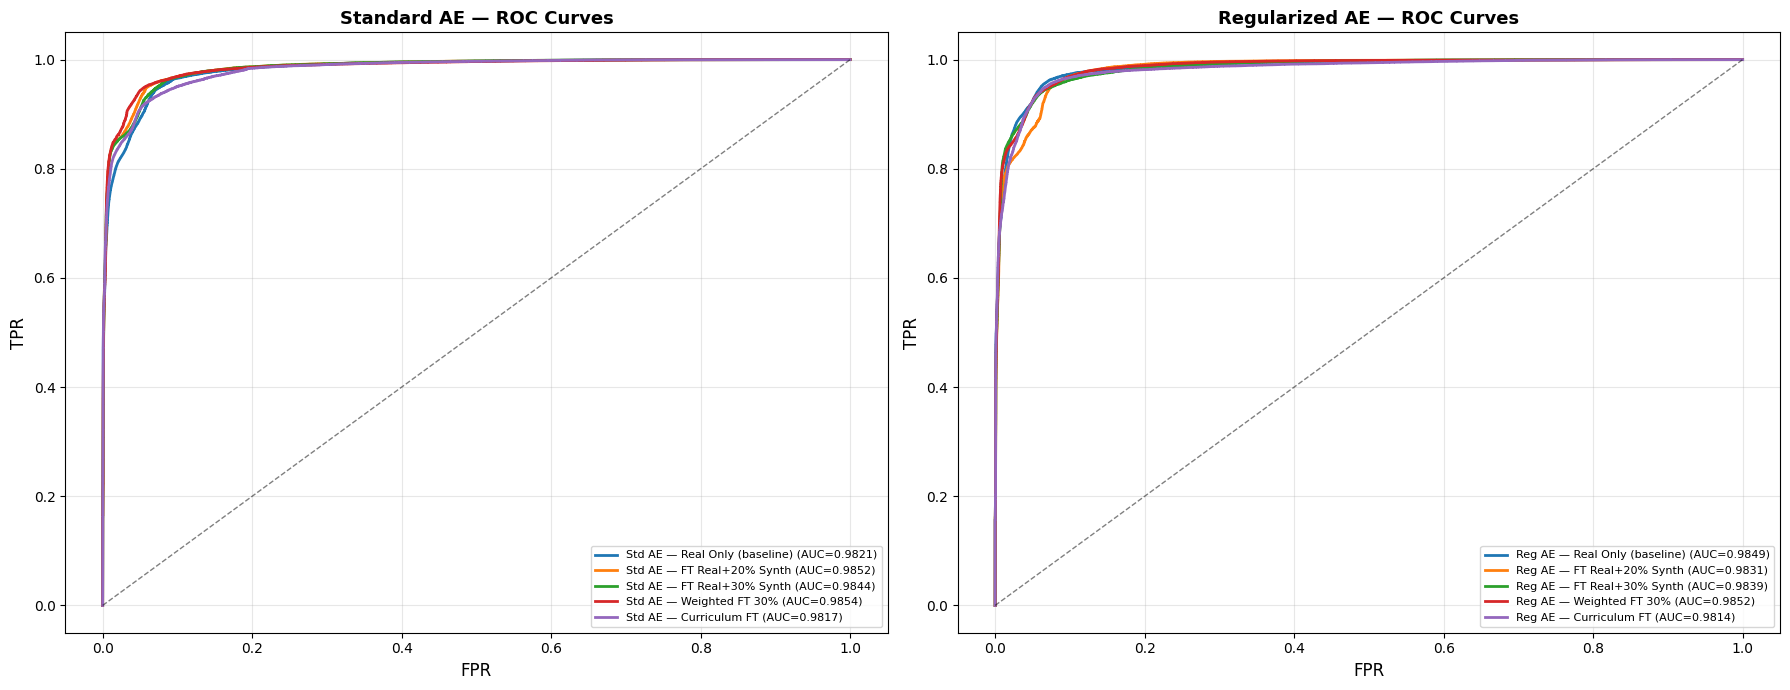

In [28]:
# ── ROC Curves for all experiments ──
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

colors = plt.cm.tab10(np.linspace(0, 1, 10))

# Standard AE experiments
ax = axes[0]
std_experiments = [(n, m) for n, m in all_experiments.items() if n.startswith('Std AE')]
for i, (name, m) in enumerate(std_experiments):
    fpr, tpr, _ = roc_curve(y_malicious, m['scores'])
    ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{name} (AUC={m['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('FPR', fontsize=12)
ax.set_ylabel('TPR', fontsize=12)
ax.set_title('Standard AE — ROC Curves', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.3)

# Regularized AE experiments
ax = axes[1]
reg_experiments = [(n, m) for n, m in all_experiments.items() if n.startswith('Reg AE')]
for i, (name, m) in enumerate(reg_experiments):
    fpr, tpr, _ = roc_curve(y_malicious, m['scores'])
    ax.plot(fpr, tpr, color=colors[i], lw=2, label=f"{name} (AUC={m['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('FPR', fontsize=12)
ax.set_ylabel('TPR', fontsize=12)
ax.set_title('Regularized AE — ROC Curves', fontsize=13, fontweight='bold')
ax.legend(fontsize=8, loc='lower right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/synthetic_augmentation_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

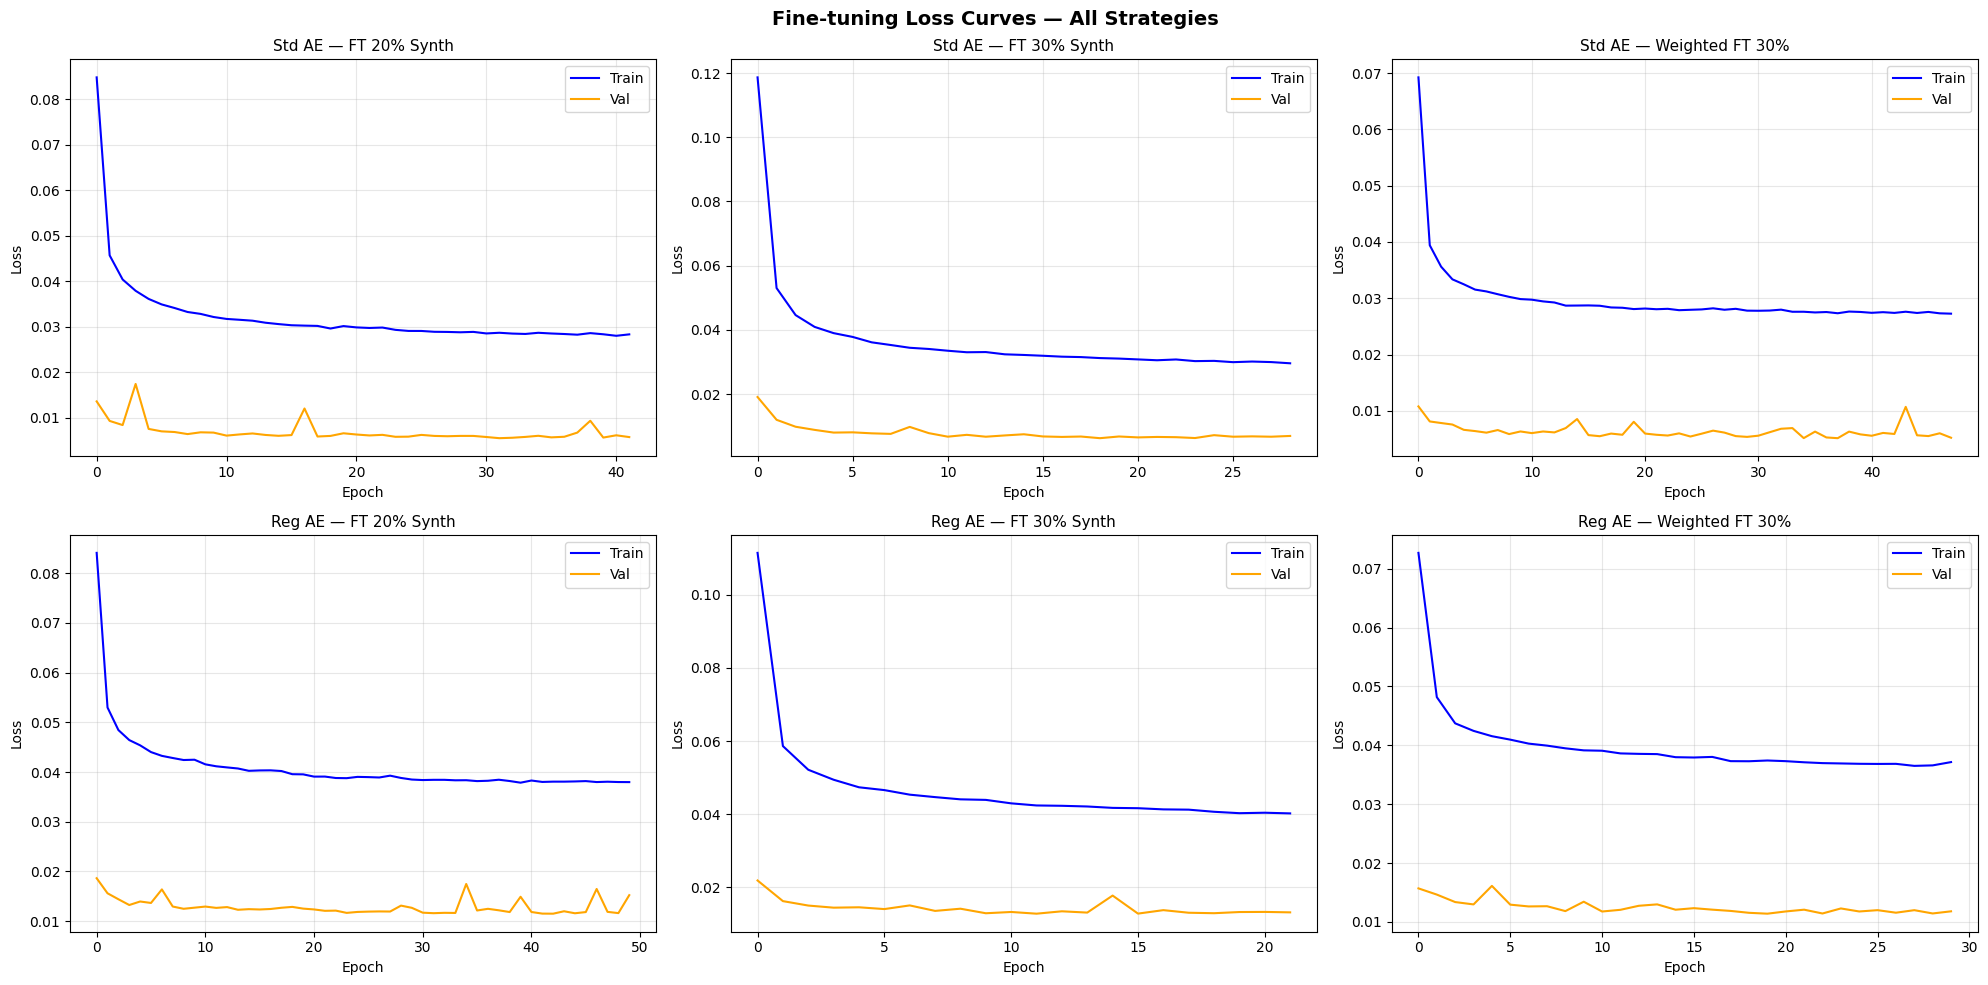

In [29]:
# ── Fine-tuning loss curves comparison ──
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle('Fine-tuning Loss Curves — All Strategies', fontsize=14, fontweight='bold')

histories_std = [
    ('FT 20% Synth', hist_ft_std_20),
    ('FT 30% Synth', hist_ft_std_30),
    ('Weighted FT 30%', hist_wt_std_30),
]
histories_reg = [
    ('FT 20% Synth', hist_ft_reg_20),
    ('FT 30% Synth', hist_ft_reg_30),
    ('Weighted FT 30%', hist_wt_reg_30),
]

for col, (title, hist) in enumerate(histories_std):
    ax = axes[0, col]
    ax.plot(hist['train_loss'], label='Train', color='blue')
    ax.plot(hist['val_loss'], label='Val', color='orange')
    ax.set_title(f'Std AE — {title}', fontsize=11)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(True, alpha=0.3)

for col, (title, hist) in enumerate(histories_reg):
    ax = axes[1, col]
    ax.plot(hist['train_loss'], label='Train', color='blue')
    ax.plot(hist['val_loss'], label='Val', color='orange')
    ax.set_title(f'Reg AE — {title}', fontsize=11)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/synthetic_finetuning_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

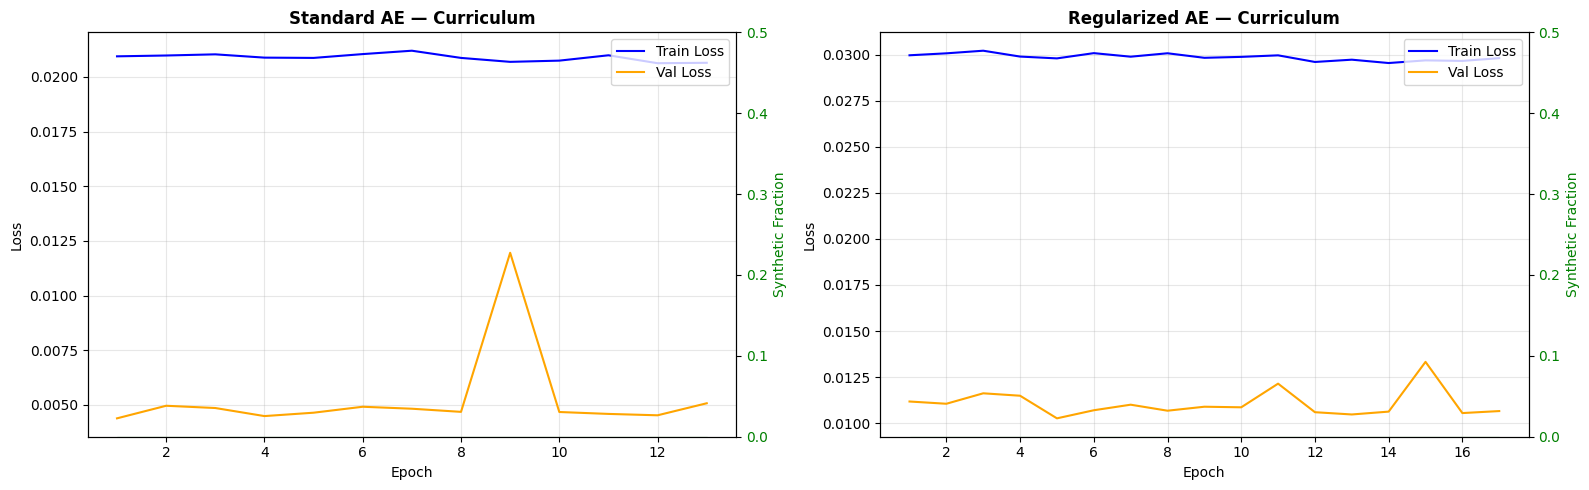

In [30]:
# ── Curriculum learning phases visualization ──
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, hist, title in zip(
    axes, [hist_cur_std, hist_cur_reg],
    ['Standard AE — Curriculum', 'Regularized AE — Curriculum']
):
    epochs_range = range(1, len(hist['train_loss'])+1)
    ax.plot(epochs_range, hist['train_loss'], label='Train Loss', color='blue')
    ax.plot(epochs_range, hist['val_loss'], label='Val Loss', color='orange')
    
    # Shade phases
    ax2 = ax.twinx()
    ax2.fill_between(epochs_range, hist['synth_fraction'], alpha=0.15, color='green', label='Synth Fraction')
    ax2.set_ylabel('Synthetic Fraction', color='green')
    ax2.set_ylim(0, 0.5)
    ax2.tick_params(axis='y', labelcolor='green')
    
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('autoencoder_outputs/curriculum_learning_phases.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 17: Bar Chart — Metric Comparison Across Experiments

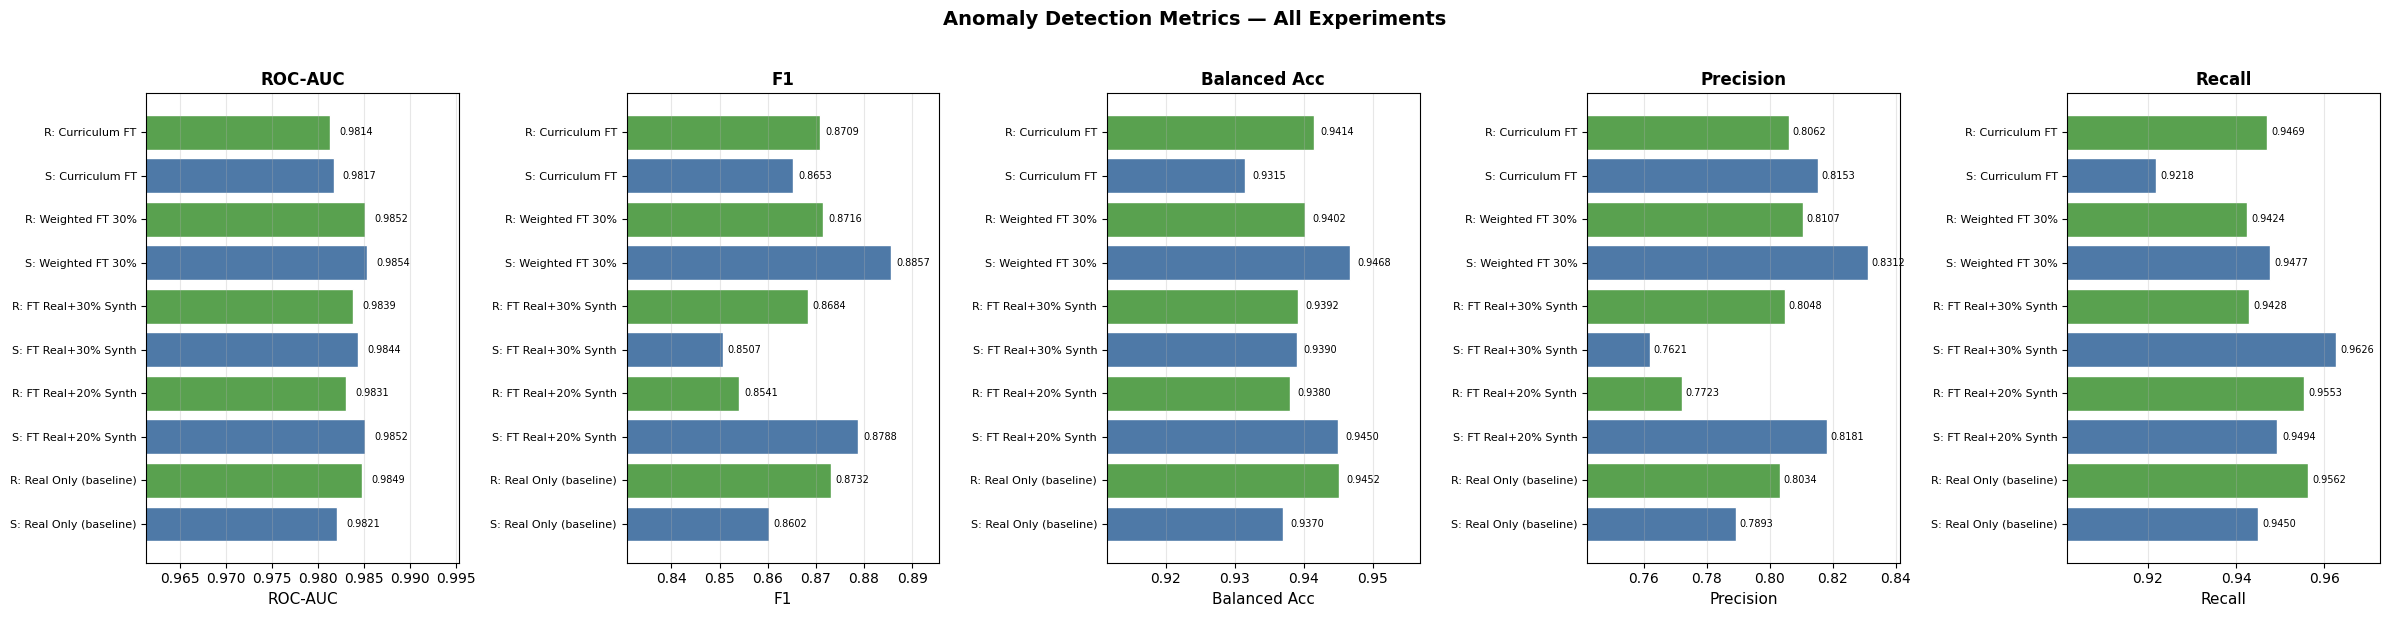

In [31]:
# ── Grouped bar chart for key metrics ──
metrics_to_show = ['ROC-AUC', 'F1', 'Balanced Acc', 'Precision', 'Recall']
experiment_names = list(display_results.keys())

fig, axes = plt.subplots(1, len(metrics_to_show), figsize=(24, 6))

# Color: blue for Standard AE, green for Regularized AE
bar_colors = ['#4e79a7' if n.startswith('Std') else '#59a14f' for n in experiment_names]

for ax, metric in zip(axes, metrics_to_show):
    vals = [display_results[n][metric] for n in experiment_names]
    short_names = [n.replace('Std AE — ', 'S: ').replace('Reg AE — ', 'R: ') for n in experiment_names]
    bars = ax.barh(range(len(vals)), vals, color=bar_colors, edgecolor='white')
    ax.set_yticks(range(len(vals)))
    ax.set_yticklabels(short_names, fontsize=8)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.set_xlim(min(vals) - 0.02, max(vals) + 0.01)
    ax.grid(True, alpha=0.3, axis='x')
    # Add value labels
    for bar, val in zip(bars, vals):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2, f'{val:.4f}', 
                va='center', fontsize=7)

plt.suptitle('Anomaly Detection Metrics — All Experiments', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('autoencoder_outputs/synthetic_augmentation_metrics_barplot.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Part 18: Save All Experiment Metrics & Models

In [32]:
output_dir = 'autoencoder_outputs'

# ── Save comparison CSV ──
comparison_df = pd.DataFrame(display_results).T
comparison_df.to_csv(f'{output_dir}/synthetic_augmentation_comparison.csv')
print("Saved: synthetic_augmentation_comparison.csv")

# ── Save fine-tuned models ──
models_to_save = {
    'ft_std_ae_20pct.pth': model_ft_std_20,
    'ft_reg_ae_20pct.pth': model_ft_reg_20,
    'ft_std_ae_30pct.pth': model_ft_std_30,
    'ft_reg_ae_30pct.pth': model_ft_reg_30,
    'wt_std_ae_30pct.pth': model_wt_std_30,
    'wt_reg_ae_30pct.pth': model_wt_reg_30,
    'cur_std_ae.pth': model_cur_std,
    'cur_reg_ae.pth': model_cur_reg,
}

for fname, model in models_to_save.items():
    torch.save(model.state_dict(), f'{output_dir}/{fname}')
    print(f"Saved: {fname}")

# ── Save synthetic data filtering info ──
filtering_info = {
    'total_synthetic_samples': int(len(X_synthetic_scaled)),
    'filtered_synthetic_samples': int(mask_keep.sum()),
    'filter_threshold': float(filter_threshold),
    'real_error_mean': float(stats_best['mean']),
    'real_error_std': float(stats_best['std']),
    'filter_method': 'mean + 2*std (or 3*std if too strict)',
}
with open(f'{output_dir}/synthetic_filtering_info.json', 'w') as f:
    json.dump(filtering_info, f, indent=2)
print("Saved: synthetic_filtering_info.json")

print(f"\nAll outputs saved to '{output_dir}/'.")

Saved: synthetic_augmentation_comparison.csv
Saved: ft_std_ae_20pct.pth
Saved: ft_reg_ae_20pct.pth
Saved: ft_std_ae_30pct.pth
Saved: ft_reg_ae_30pct.pth
Saved: wt_std_ae_30pct.pth
Saved: wt_reg_ae_30pct.pth
Saved: cur_std_ae.pth
Saved: cur_reg_ae.pth
Saved: synthetic_filtering_info.json

All outputs saved to 'autoencoder_outputs/'.


---
## Part 19: Final Summary & Recommendations

### Experiments Conducted
| # | Experiment | Description |
|---|-----------|-------------|
| 1 | Real Only (baseline) | Pretrained models from TP1, no synthetic data |
| 2 | Test on Synthetic | Run pretrained models on synthetic attack sequences |
| 3 | FT Real+20% Synth | Fine-tune pretrained models with 20% filtered synthetic data |
| 4 | FT Real+30% Synth | Fine-tune pretrained models with 30% filtered synthetic data |
| 5 | Weighted Loss | Fine-tune with weighted MSE (real=1.0, synth=0.3) |
| 6 | Curriculum | Gradual introduction: 0% → 15% → 30% synthetic data |

### Key Design Choices
- **Filtering:** Synthetic samples with reconstruction error within real-data distribution (mean ± 2σ) are kept
- **Fine-tuning:** Smaller learning rate (1e-4 vs 1e-3 for initial training) to preserve learned representations
- **Weighted loss:** Real samples weighted 1.0, synthetic weighted 0.3 to prioritize real data fidelity
- **Curriculum:** 3 phases of equal length, progressively increasing synthetic ratio

In [33]:
# ── Print final summary table ──
print("="*100)
print(f"{'FINAL SUMMARY: Synthetic Data Augmentation for Autoencoder Anomaly Detection':^100}")
print("="*100)

print(f"\n{'Model / Strategy':<45} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10} {'ΔAUC vs Base':>14}")
print("-"*89)

ref_std = display_results['Std AE — Real Only (baseline)']['ROC-AUC']
ref_reg = display_results['Reg AE — Real Only (baseline)']['ROC-AUC']

for name, m in display_results.items():
    ref = ref_std if name.startswith('Std') else ref_reg
    delta = m['ROC-AUC'] - ref
    marker = '★' if name in ['Std AE — Real Only (baseline)', 'Reg AE — Real Only (baseline)'] else ''
    print(f"{marker}{name:<44} {m['ROC-AUC']:>10.4f} {m['F1']:>10.4f} {m['Balanced Acc']:>10.4f} {delta:>+14.4f}")

print("\n" + "="*100)
print(f"Synthetic data source: ckc_attack_sequences.xlsx (ReALTabFormer)")
print(f"Total synthetic: {len(X_synthetic_scaled):,} | Filtered: {mask_keep.sum():,} ({mask_keep.mean()*100:.1f}%)")
print(f"Feature set: Top 25 conceptual → {len(selected_columns)} actual columns")
print(f"Real data: {len(X_real_scaled):,} samples ({(y_malicious==0).sum():,} benign, {(y_malicious==1).sum():,} malicious)")
print("="*100)

            FINAL SUMMARY: Synthetic Data Augmentation for Autoencoder Anomaly Detection            

Model / Strategy                                 ROC-AUC         F1    Bal.Acc   ΔAUC vs Base
-----------------------------------------------------------------------------------------
★Std AE — Real Only (baseline)                    0.9821     0.8602     0.9370        +0.0000
★Reg AE — Real Only (baseline)                    0.9849     0.8732     0.9452        +0.0000
Std AE — FT Real+20% Synth                       0.9852     0.8788     0.9450        +0.0031
Reg AE — FT Real+20% Synth                       0.9831     0.8541     0.9380        -0.0018
Std AE — FT Real+30% Synth                       0.9844     0.8507     0.9390        +0.0023
Reg AE — FT Real+30% Synth                       0.9839     0.8684     0.9392        -0.0010
Std AE — Weighted FT 30%                         0.9854     0.8857     0.9468        +0.0033
Reg AE — Weighted FT 30%                         0.9852     0